In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:
url = "https://raw.githubusercontent.com/mranuraggarg/retail_sales_dataset/main/data/retail_sales_dataset.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000, 9)


,trans_id,s_date,cust_id,gender,age,prod_cat,quantity,price_per_unit,amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
print("Dataset information:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe(include="all"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   trans_id        1000 non-null   int64 
 1   s_date          1000 non-null   object
 2   cust_id         1000 non-null   object
 3   gender          1000 non-null   object
 4   age             1000 non-null   int64 
 5   prod_cat        1000 non-null   object
 6   quantity        1000 non-null   int64 
 7   price_per_unit  1000 non-null   int64 
 8   amount          1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing values per column:


,0
trans_id,0
s_date,0
cust_id,0
gender,0
age,0
prod_cat,0
quantity,0
price_per_unit,0
amount,0



Duplicate rows: 0

Summary statistics:


,trans_id,s_date,cust_id,gender,age,prod_cat,quantity,price_per_unit,amount
count,1000.000000,1000,1000,1000,1000.00000,1000,1000.000000,1000.000000,1000.000000
unique,NaN,345,1000,2,NaN,3,NaN,NaN,NaN
top,NaN,2023-05-16,CUST1000,Female,NaN,Clothing,NaN,NaN,NaN
freq,NaN,11,1,510,NaN,351,NaN,NaN,NaN
mean,500.500000,NaN,NaN,NaN,41.39200,NaN,2.514000,179.890000,456.000000
std,288.819436,NaN,NaN,NaN,13.68143,NaN,1.132734,189.681356,559.997632
min,1.000000,NaN,NaN,NaN,18.00000,NaN,1.000000,25.000000,25.000000
25%,250.750000,NaN,NaN,NaN,29.00000,NaN,1.000000,30.000000,60.000000
50%,500.500000,NaN,NaN,NaN,42.00000,NaN,3.000000,50.000000,135.000000
75%,750.250000,NaN,NaN,NaN,53.00000,NaN,4.000000,300.000000,900.000000


In [5]:
print("Product categories:")
display(df["prod_cat"].value_counts())

print("\nTransactions by gender:")
display(df["gender"].value_counts())

print("\nRevenue by product category:")
category_sales = (
    df.groupby("prod_cat")["amount"]
      .sum()
      .sort_values(ascending=False)
)
display(category_sales)

Product categories:


,count
prod_cat,
Clothing,351
Electronics,342
Beauty,307



Transactions by gender:


,count
gender,
Female,510
Male,490



Revenue by product category:


,amount
prod_cat,
Electronics,156905
Clothing,155580
Beauty,143515


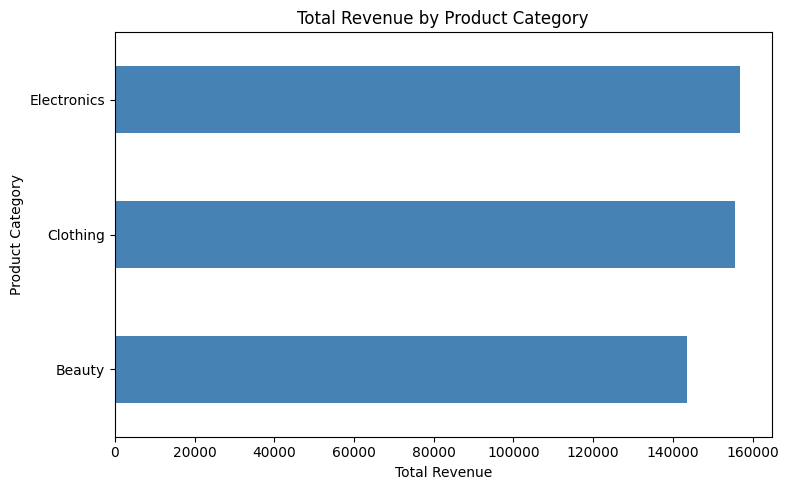

In [6]:
plt.figure(figsize=(8, 5))

category_sales.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [7]:
df["s_date"] = pd.to_datetime(df["s_date"])

df["month"] = df["s_date"].dt.to_period("M")

monthly_sales = df.groupby("month")["amount"].sum()

print("Monthly revenue:")
display(monthly_sales)

Monthly revenue:


,amount
month,
2023-01,35450
2023-02,44060
2023-03,28990
2023-04,33870
2023-05,53150
2023-06,36715
2023-07,35465
2023-08,36960
2023-09,23620


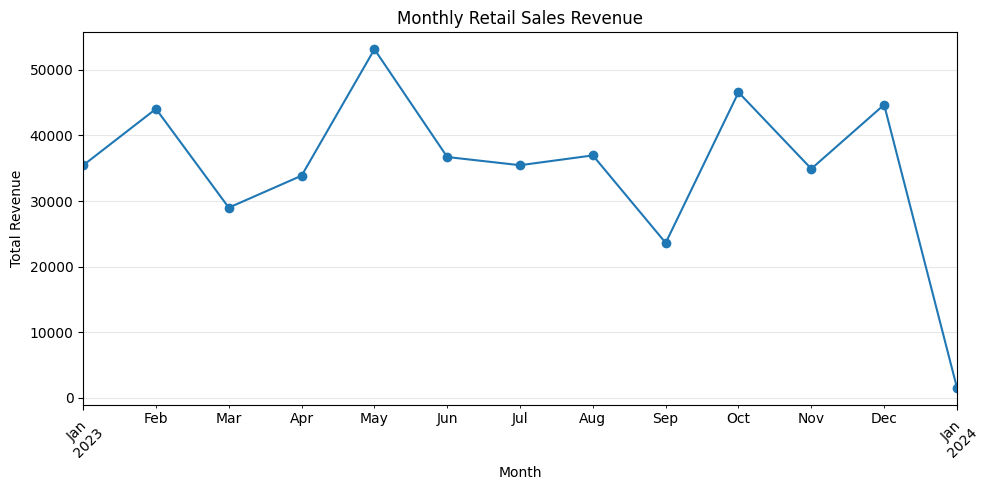

In [8]:
plt.figure(figsize=(10, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Retail Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
category_summary = df.groupby("prod_cat").agg(
    Transactions=("trans_id", "count"),
    Total_Revenue=("amount", "sum"),
    Average_Transaction=("amount", "mean")
).sort_values("Total_Revenue", ascending=False)

display(category_summary.round(2))

,Transactions,Total_Revenue,Average_Transaction
prod_cat,,,
Electronics,342,156905,458.79
Clothing,351,155580,443.25
Beauty,307,143515,467.48


In [10]:
gender_summary = df.groupby("gender").agg(
    Transactions=("trans_id", "count"),
    Total_Revenue=("amount", "sum"),
    Average_Spending=("amount", "mean")
)

display(gender_summary.round(2))

,Transactions,Total_Revenue,Average_Spending
gender,,,
Female,510,232840,456.55
Male,490,223160,455.43


## Key Findings and Conclusion

- The dataset contains 1,000 transactions across three product categories, with no missing values or duplicate rows detected.
- Clothing recorded the highest transaction count, while Electronics generated the highest total revenue.
- Monthly revenue varied across the observed period, peaking in May 2023. January 2024 contains only a small amount of revenue and may represent a partial month.
- These findings describe patterns in the available data. Additional context would be needed to explain the reasons behind the differences.

This exploratory analysis used Python, pandas, Matplotlib and Seaborn to inspect the dataset, summarise sales performance and visualise revenue patterns.